# Exploratory Data Analysis (EDA)



In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

In [2]:
DATA_DIR = Path("../data/raw")
SPARKOV_TRAIN_PATH = DATA_DIR / "fraudTrain.csv"
IEEE_TRANSACTION_PATH = DATA_DIR / "train_transaction.csv"

def read_csv_checked(path):
    if not Path(path).exists():
        raise FileNotFoundError(f"File not found: {Path(path).resolve()}")
    print(f"Reading {path} ...")
    return pd.read_csv(path, low_memory=False)

sparkov = read_csv_checked(SPARKOV_TRAIN_PATH)
ieee = read_csv_checked(IEEE_TRANSACTION_PATH)
print(f"Sparkov: {sparkov.shape[0]:,} rows, {sparkov.shape[1]:,} columns")
print(f"IEEE-CIS: {ieee.shape[0]:,} rows, {ieee.shape[1]:,} columns")

Reading ..\data\raw\fraudTrain.csv ...
Reading ..\data\raw\train_transaction.csv ...
Sparkov: 1,296,675 rows, 23 columns
IEEE-CIS: 590,540 rows, 394 columns


## Helper Functions

In [3]:
def fraud_rate_table(df, label_col, group_col, min_count=1):
    data = df.dropna(subset=[label_col, group_col]).copy()
    result = data.groupby(group_col)[label_col].agg(
        transactions="size", frauds="sum", fraud_rate="mean"
    ).reset_index()
    result = result[result["transactions"] >= min_count].copy()
    result["fraud_rate_pct"] = result["fraud_rate"] * 100
    return result.sort_values("fraud_rate", ascending=False)

def plot_fraud_rate(df, label_col, time_col, title, period="M"):
    data = df[[label_col, time_col]].dropna().copy()
    data[time_col] = pd.to_datetime(data[time_col], errors="coerce")
    data = data.dropna(subset=[time_col])
    data["period"] = data[time_col].dt.to_period(period).dt.to_timestamp()
    grouped = data.groupby("period")[label_col].agg(transactions="size", frauds="sum")
    grouped["fraud_rate_pct"] = grouped["frauds"] / grouped["transactions"] * 100
    fig, ax = plt.subplots(figsize=(13, 4))
    sns.lineplot(data=grouped, x=grouped.index, y="fraud_rate_pct", marker="o", ax=ax)
    ax.set(title=title, xlabel="Period", ylabel="Fraud rate (%)")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    return grouped

## Sparkov

#### Amount and Temporal patterns

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


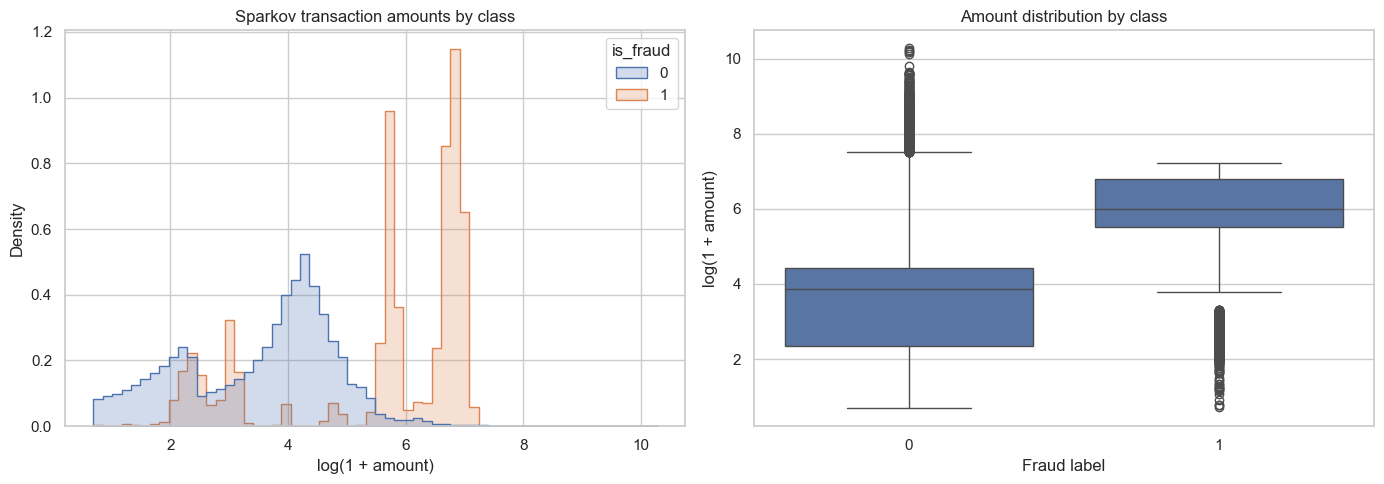

In [ ]:
sparkov["transaction_datetime"] = pd.to_datetime(sparkov["trans_date_trans_time"], errors="coerce")
sparkov["amount_log"] = np.log1p(sparkov["amt"].clip(lower=0))

# transaction amount is compressed by log, large numbers are compressed, small numbers stay apart

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=sparkov, x="amount_log", hue="is_fraud", bins=60, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Sparkov transaction amounts by class", xlabel="log(1 + amount)")
sns.boxplot(data=sparkov, x="is_fraud", y="amount_log", ax=axes[1])
axes[1].set(title="Amount distribution by class", xlabel="Fraud label", ylabel="log(1 + amount)")
plt.tight_layout()

display(sparkov.groupby("is_fraud")["amt"].describe())

,transactions,frauds,fraud_rate_pct
period,,,
2019-01-01,52525,506,0.963351
2019-02-01,49866,517,1.036779
2019-03-01,70939,494,0.696373
2019-04-01,68078,376,0.552308
2019-05-01,72532,408,0.562510


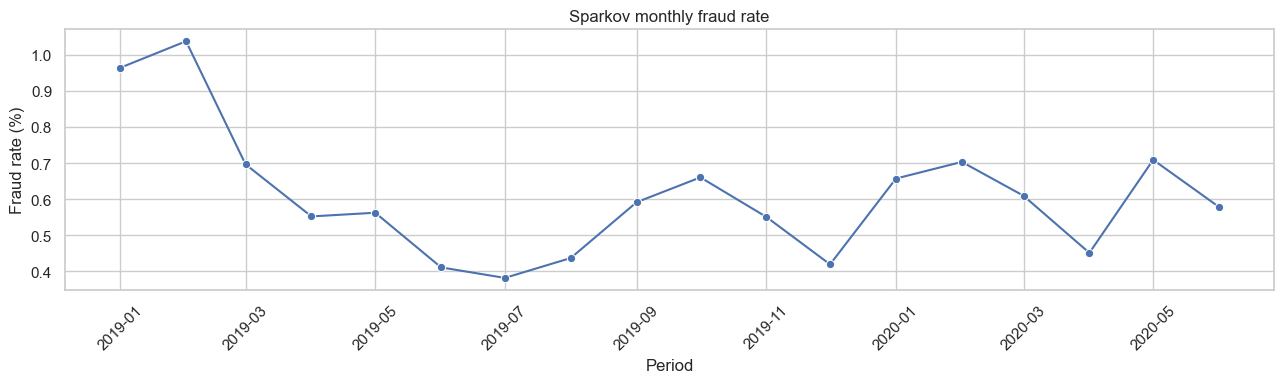

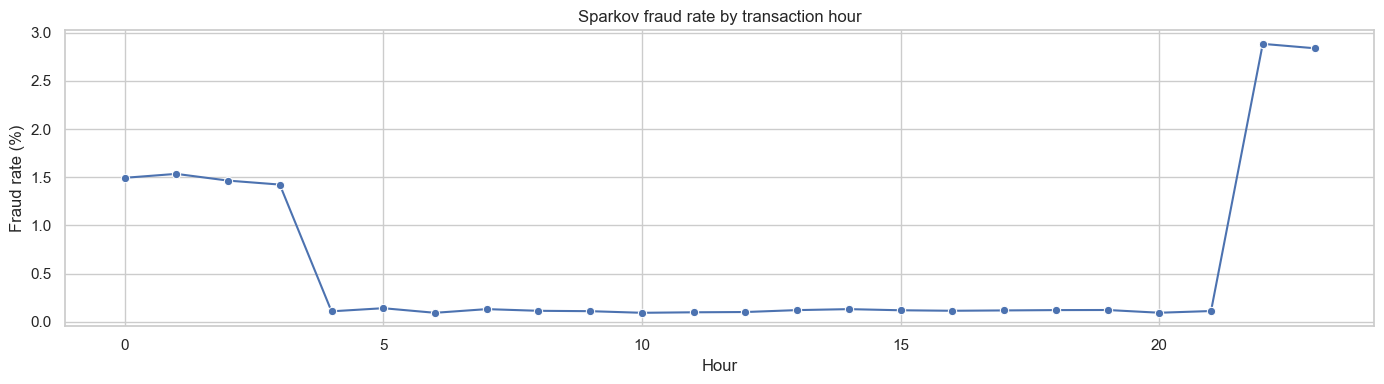

In [7]:
sparkov_monthly = plot_fraud_rate(
    sparkov, "is_fraud", "transaction_datetime",
    "Sparkov monthly fraud rate", period="M"
)
display(sparkov_monthly.head())

sparkov["hour"] = sparkov["transaction_datetime"].dt.hour
hourly = sparkov.groupby("hour")["is_fraud"].agg(transactions="size", frauds="sum")
hourly["fraud_rate_pct"] = hourly["frauds"] / hourly["transactions"] * 100

fig, axes = plt.subplots(figsize=(14, 4))
sns.lineplot(data=hourly, x=hourly.index, y="fraud_rate_pct", marker="o", ax=axes)
axes.set(title="Sparkov fraud rate by transaction hour", xlabel="Hour", ylabel="Fraud rate (%)")

plt.tight_layout()

#### Merchant Category & Card activity

,category,transactions,frauds,fraud_rate,fraud_rate_pct
11,shopping_net,97543,1713,0.017561,1.756149
8,misc_net,63287,915,0.014458,1.445795
4,grocery_pos,123638,1743,0.014098,1.409761
12,shopping_pos,116672,843,0.007225,0.722538
2,gas_transport,131659,618,0.004694,0.469394
9,misc_pos,79655,250,0.003139,0.313853
3,grocery_net,45452,134,0.002948,0.294817
13,travel,40507,116,0.002864,0.286370
0,entertainment,94014,233,0.002478,0.247835
10,personal_care,90758,220,0.002424,0.242403


,cc_num,transactions,frauds,fraud_rate,total_amount,fraud_rate_pct
28,571365235126,3123,10,0.003202,191918.03,0.320205
943,4512828414983801773,3123,0,0.000000,172868.53,0.000000
222,36722699017270,3119,7,0.002244,280008.05,0.224431
272,213112402583773,3117,0,0.000000,179368.37,0.000000
531,3545109339866548,3113,0,0.000000,150914.97,0.000000
869,6534628260579800,3112,15,0.004820,163214.11,0.482005
822,6011367958204270,3110,0,0.000000,296436.73,0.000000
452,2720433095629877,3107,16,0.005150,164002.26,0.514966
828,6011438889172900,3106,14,0.004507,284013.50,0.450741
811,6011109736646996,3101,2,0.000645,278139.27,0.064495


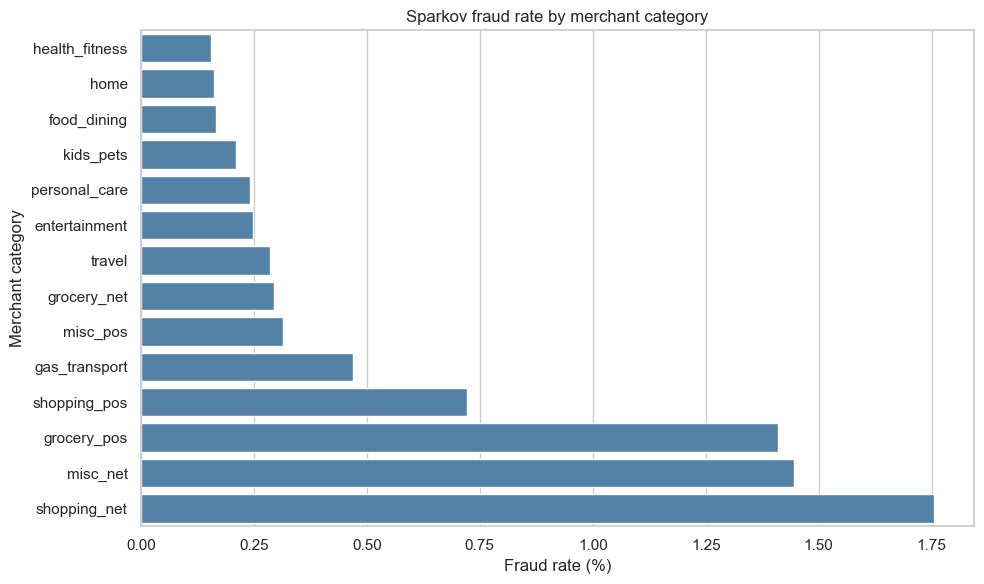

In [ ]:
category_rates = fraud_rate_table(sparkov, "is_fraud", "category", min_count=500)
# Note: a min_count here is set, so small categories (eg. have 5 transactions, 4 of them are frauduluent, will be skewed)
# Feel free to edit ya

display(category_rates.head(15))

plt.figure(figsize=(10, 6))
plot_data = category_rates.sort_values("fraud_rate_pct", ascending=True)
sns.barplot(data=plot_data, x="fraud_rate_pct", y="category", color="steelblue")
plt.title("Sparkov fraud rate by merchant category")
plt.xlabel("Fraud rate (%)")
plt.ylabel("Merchant category")
plt.tight_layout()

card_activity = sparkov.groupby("cc_num").agg(
    transactions=("is_fraud", "size"),
    frauds=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
    total_amount=("amt", "sum")
    ).reset_index()
card_activity["fraud_rate_pct"] = card_activity["fraud_rate"] * 100
display(card_activity.sort_values("transactions", ascending=False).head(15))

### IEEE-CIS

#### Transaction amount, relative time
* `TransactionDT` is elapsed time, hence shown as relative days (and not calendar date)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


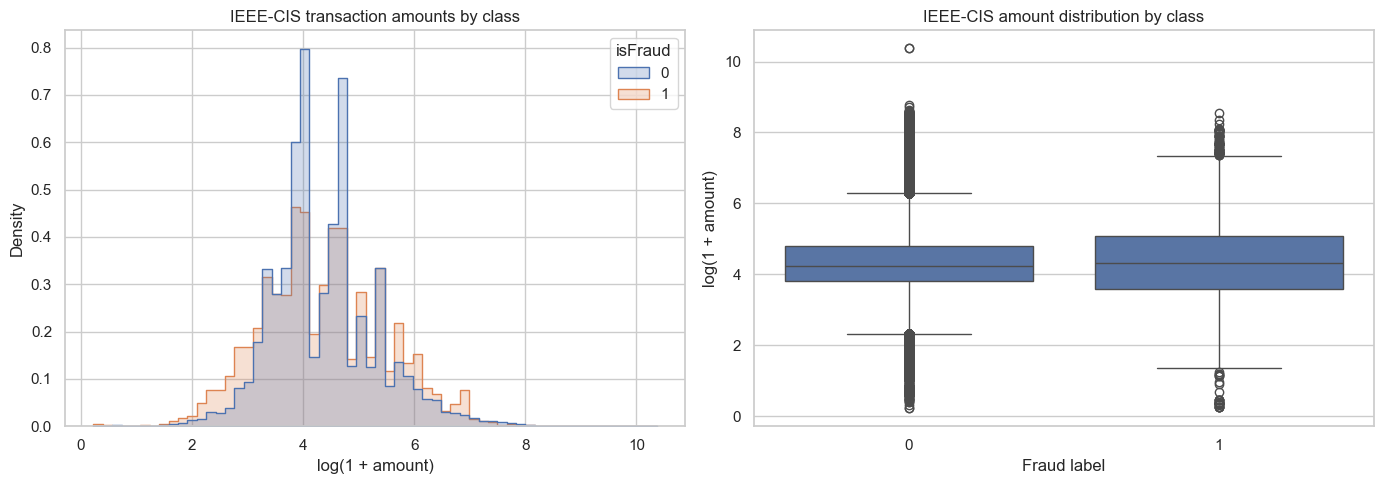

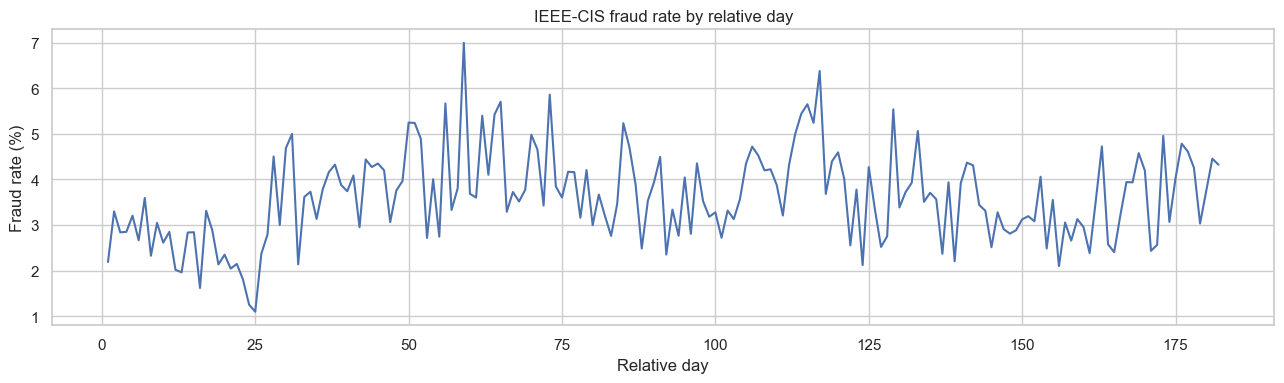

In [9]:
ieee["amount_log"] = np.log1p(ieee["TransactionAmt"].clip(lower=0))
ieee["relative_day"] = ieee["TransactionDT"] // 86400

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=ieee, x="amount_log", hue="isFraud", bins=60, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="IEEE-CIS transaction amounts by class", xlabel="log(1 + amount)")
sns.boxplot(data=ieee, x="isFraud", y="amount_log", ax=axes[1])
axes[1].set(title="IEEE-CIS amount distribution by class", xlabel="Fraud label", ylabel="log(1 + amount)")
plt.tight_layout()
display(ieee.groupby("isFraud")["TransactionAmt"].describe())

ieee_daily = ieee.groupby("relative_day")["isFraud"].agg(transactions="size", frauds="sum")
ieee_daily["fraud_rate_pct"] = ieee_daily["frauds"] / ieee_daily["transactions"] * 100
plt.figure(figsize=(13, 4))
sns.lineplot(data=ieee_daily, x=ieee_daily.index, y="fraud_rate_pct")
plt.title("IEEE-CIS fraud rate by relative day")
plt.xlabel("Relative day")
plt.ylabel("Fraud rate (%)")
plt.tight_layout()

,ProductCD,transactions,frauds,fraud_rate,fraud_rate_pct
0,C,68519,8008,0.116873,11.687269
3,S,11628,686,0.058996,5.899553
1,H,33024,1574,0.047662,4.766231
2,R,37699,1426,0.037826,3.782594
4,W,439670,8969,0.020399,2.039939


,card1,transactions,frauds,fraud_rate,fraud_rate_pct
6938,9917,919,306,0.332971,33.297062
10364,14276,894,252,0.281879,28.187919
7703,10876,750,186,0.248000,24.800000
2718,4504,974,210,0.215606,21.560575
7460,10568,925,190,0.205405,20.540541
6262,9026,2076,397,0.191233,19.123314
773,1976,928,177,0.190733,19.073276
6035,8755,1110,199,0.179279,17.927928
6715,9633,4158,742,0.178451,17.845118
983,2256,1343,235,0.174981,17.498138


,card2,transactions,frauds,fraud_rate,fraud_rate_pct
75,176.0,513,185,0.360624,36.062378
4,104.0,754,187,0.248011,24.801061
76,177.0,1642,396,0.241169,24.116931
41,142.0,1685,405,0.240356,24.035608
29,130.0,2746,657,0.239257,23.925710
358,459.0,677,135,0.199409,19.940916
195,296.0,2516,483,0.191971,19.197138
165,266.0,872,167,0.191514,19.151376
399,500.0,5045,911,0.180575,18.057483
428,529.0,754,136,0.180371,18.037135


,card3,transactions,frauds,fraud_rate,fraud_rate_pct
73,185.0,56346,7362,0.130657,13.065701
13,119.0,750,70,0.093333,9.333333
37,144.0,1252,112,0.089457,8.945687
36,143.0,899,28,0.031146,3.114572
42,150.0,521287,12807,0.024568,2.456804
38,146.0,1252,25,0.019968,1.996805
11,117.0,962,18,0.018711,1.871102
4,106.0,1571,24,0.015277,1.527689


,card4,transactions,frauds,fraud_rate,fraud_rate_pct
1,discover,6651,514,0.077282,7.728161
3,visa,384767,13373,0.034756,3.475610
2,mastercard,189217,6496,0.034331,3.433095
0,american express,8328,239,0.028698,2.869837


,card5,transactions,frauds,fraud_rate,fraud_rate_pct
33,137.0,11720,1725,0.147184,14.718430
105,223.0,936,83,0.088675,8.867521
34,138.0,19737,1682,0.085221,8.522065
54,162.0,4524,301,0.066534,6.653404
2,102.0,29105,1832,0.062945,6.294451
102,219.0,9924,571,0.057537,5.753728
82,197.0,1551,86,0.055448,5.544810
83,198.0,670,34,0.050746,5.074627
80,195.0,16945,681,0.040189,4.018885
106,224.0,81513,3152,0.038669,3.866868


,card6,transactions,frauds,fraud_rate,fraud_rate_pct
1,credit,148986,9950,0.066785,6.678480
2,debit,439938,10674,0.024263,2.426251


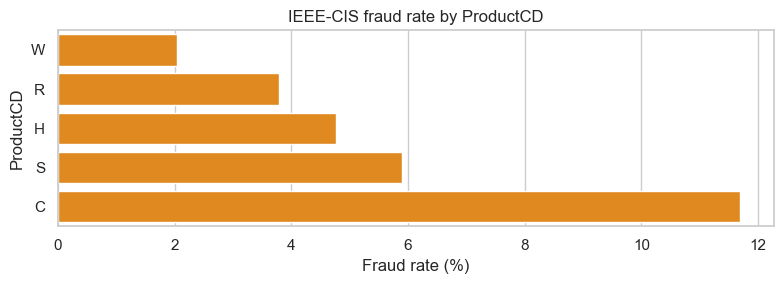

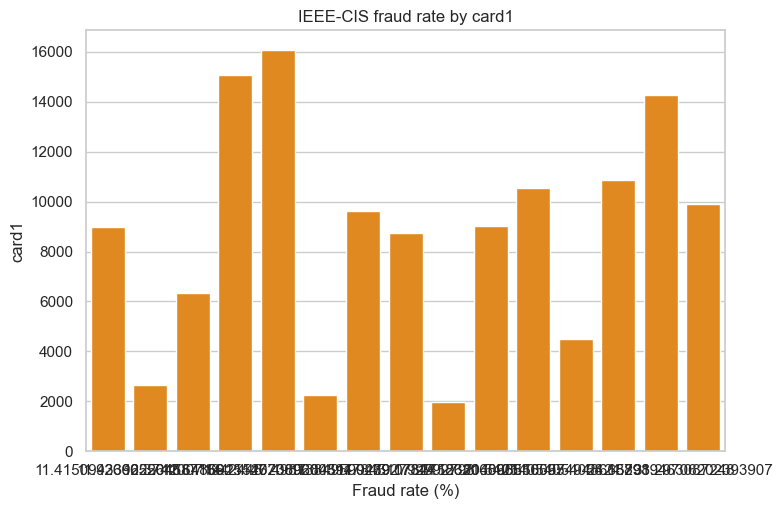

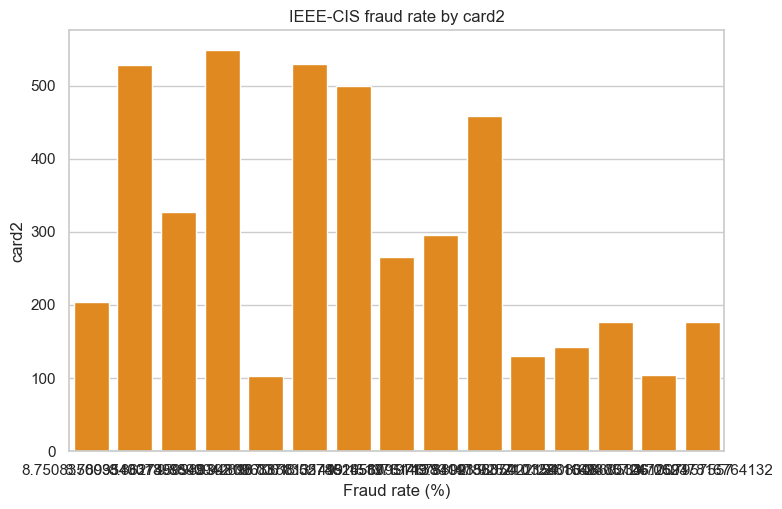

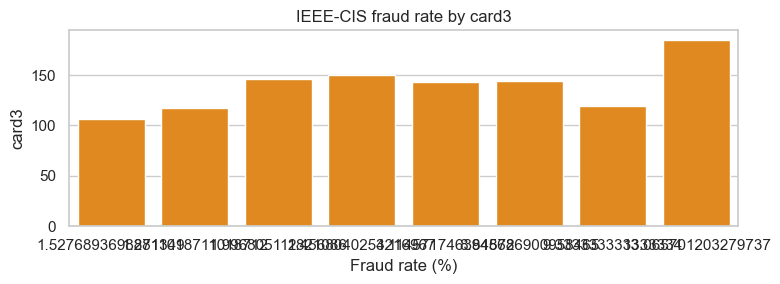

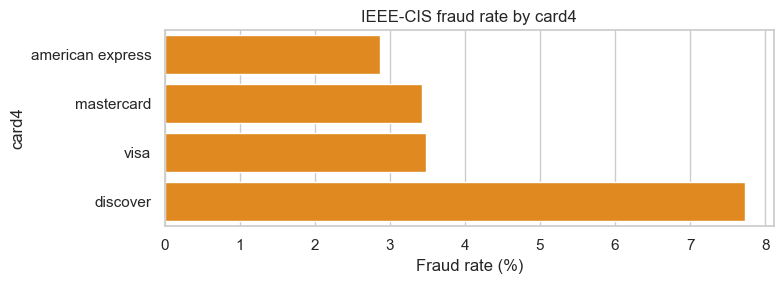

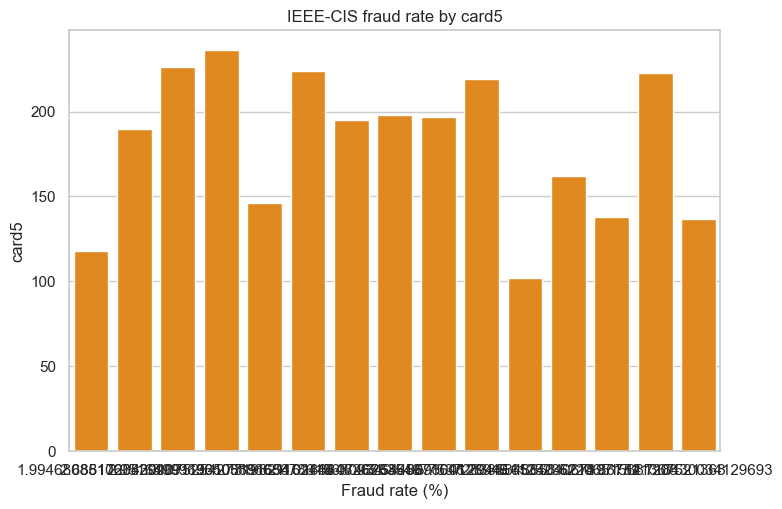

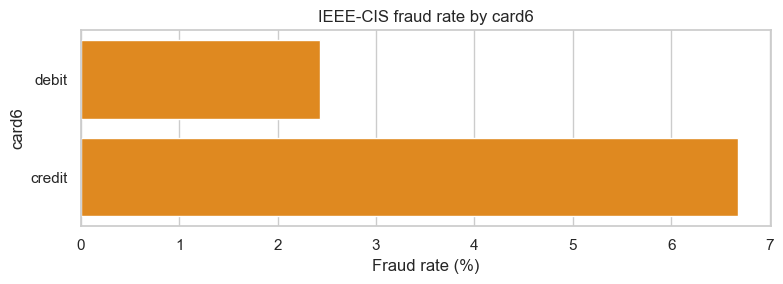

In [11]:
# Compare fraud rates for selected categorical IEEE-CIS variables.
for column in ["ProductCD", "card1", "card2", "card3", "card4","card5", "card6", "DeviceType"]:
    if column not in ieee.columns:
        continue
    rates = fraud_rate_table(ieee, "isFraud", column, min_count=500)
    display(rates.head(15))
    plt.figure(figsize=(8, max(3, 0.35 * len(rates.head(15)))))
    sns.barplot(data=rates.head(15).sort_values("fraud_rate_pct"), x="fraud_rate_pct", y=column, color="darkorange")
    plt.title(f"IEEE-CIS fraud rate by {column}")
    plt.xlabel("Fraud rate (%)")
    plt.tight_layout()

### Distribution shifts over time
* compare the earliest vs latest portion. KS Statistic measure the difference between 2 distributions. Large statistic = larger difference in distribution (* Need to use p value to measure statistical significance)

In [12]:
def early_late_ks(df, time_col, feature_cols, fraction=0.2):
    ordered = df.dropna(subset=[time_col]).sort_values(time_col)
    n = max(1, int(len(ordered) * fraction))
    early, late = ordered.head(n), ordered.tail(n)
    rows = []
    for col in feature_cols:
        if col not in df.columns or not pd.api.types.is_numeric_dtype(df[col]):
            continue
        x, y = early[col].dropna(), late[col].dropna()
        if len(x) < 20 or len(y) < 20:
            continue
        stat, p_value = ks_2samp(x, y)
        rows.append({"feature": col, "ks_statistic": stat, "p_value": p_value,
                     "early_median": x.median(), "late_median": y.median()})
    return pd.DataFrame(rows).sort_values("ks_statistic", ascending=False)

sparkov_shift = early_late_ks(
    sparkov, "transaction_datetime", ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
)
display(sparkov_shift)

ieee_shift = early_late_ks(
    ieee, "TransactionDT", ["TransactionAmt"] + [c for c in ieee.columns if c.startswith("C") or c.startswith("D")][:30]
)
display(ieee_shift.head(20))

,feature,ks_statistic,p_value,early_median,late_median
1,city_pop,0.004535,0.009632,2456.000000,2408.000000
4,merch_lat,0.003563,0.074164,39.355368,39.378282
2,lat,0.002919,0.218754,39.354300,39.371600
3,long,0.002156,0.582555,-87.461600,-87.476900
0,amt,0.002132,0.596434,47.650000,47.800000
5,merch_long,0.001835,0.774144,-87.421221,-87.431618


,feature,ks_statistic,p_value,early_median,late_median
9,C9,0.288803,0.000000e+00,0.000000,1.0
8,C8,0.241965,0.000000e+00,0.000000,0.0
10,C10,0.240043,0.000000e+00,0.000000,0.0
4,C4,0.190639,0.000000e+00,0.000000,0.0
15,D1,0.185067,0.000000e+00,0.000000,14.0
20,D6,0.180992,3.849771e-216,0.000000,0.0
13,C13,0.174086,0.000000e+00,1.000000,3.0
27,D13,0.169169,8.896882e-152,0.000000,0.0
29,D15,0.152378,0.000000e+00,42.000000,73.0
28,D14,0.141814,3.197766e-113,0.000000,0.0
